# Istruzione, disoccupazione giovanile e crescita economica nei Paesi UE


**Analisi esplorativa dei 27 Paesi dell’Unione Europea, 2014–2024**

## Domanda di ricerca

Come si associano, tra i Paesi UE, il livello d’istruzione dei giovani, la disoccupazione giovanile e la crescita del PIL pro capite? Le associazioni restano simili nel tempo e quando confrontiamo i cambiamenti tra il 2014 e il 2024?

## Dati e metodo

L’analisi unisce dati annuali della Banca Mondiale e di Eurostat. Include 297 osservazioni Paese-anno: 27 Paesi per 11 anni. Usa grafici, statistiche descrittive e correlazioni per studiare le associazioni tra gli indicatori.

Le misure d’istruzione riguardano i 20–24enni; il tasso di disoccupazione riguarda la forza lavoro di 15–24 anni. I risultati sono descrittivi: le correlazioni non dimostrano rapporti di causa ed effetto.

In [1]:
import sys

print("Versione Python:", sys.version)
print("Notebook pronto.")

Versione Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Notebook pronto.


In [2]:
import requests
import pandas as pd

url = (
    "https://api.worldbank.org/v2/country/EUU/"
    "indicator/SL.UEM.1524.ZS"
    "?date=2000:2024&format=json&per_page=100"
)

risposta = requests.get(url)
risposta.raise_for_status()

dati = risposta.json()[1]
df = pd.DataFrame(dati)

df = df[["country", "date", "value"]].rename(columns={
    "country": "paese",
    "date": "anno",
    "value": "disoccupazione_giovanile_percentuale"
})

df = df.dropna(subset=["disoccupazione_giovanile_percentuale"])
df["anno"] = df["anno"].astype(int)
df = df.sort_values("anno").reset_index(drop=True)

display(df.head())

,paese,anno,disoccupazione_giovanile_percentuale
0,"{'id': 'EU', 'value': 'European Union'}",2000,20.672038
1,"{'id': 'EU', 'value': 'European Union'}",2001,20.179997
2,"{'id': 'EU', 'value': 'European Union'}",2002,20.985742
3,"{'id': 'EU', 'value': 'European Union'}",2003,20.953935
4,"{'id': 'EU', 'value': 'European Union'}",2004,21.347117


In [3]:
df["paese"] = df["paese"].apply(lambda paese: paese["value"])

print("Dimensioni della tabella:", df.shape)
display(df.head())
display(df.tail())

Dimensioni della tabella: (25, 3)


,paese,anno,disoccupazione_giovanile_percentuale
0,European Union,2000,20.672038
1,European Union,2001,20.179997
2,European Union,2002,20.985742
3,European Union,2003,20.953935
4,European Union,2004,21.347117


,paese,anno,disoccupazione_giovanile_percentuale
20,European Union,2020,19.014315
21,European Union,2021,18.737740
22,European Union,2022,16.364845
23,European Union,2023,16.231918
24,European Union,2024,16.239186


         paese  anno  disoccupazione_giovanile_percentuale
European Union  2020                             19.014315
European Union  2021                             18.737740
European Union  2022                             16.364845
European Union  2023                             16.231918
European Union  2024                             16.239186


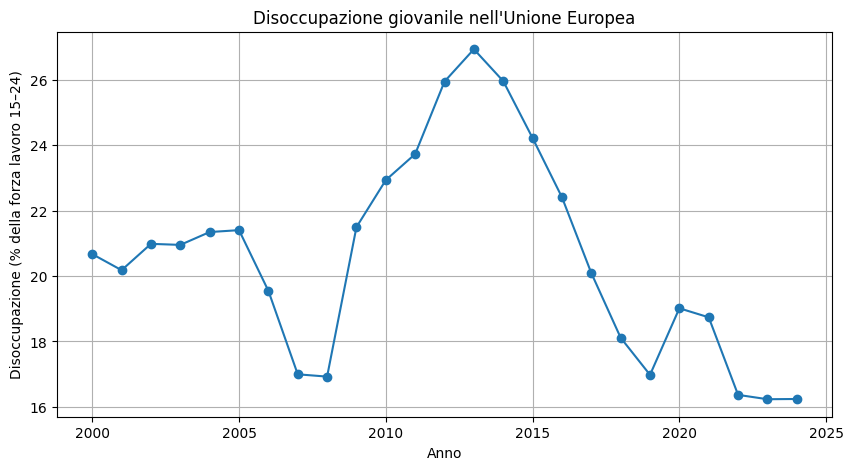

In [4]:
import matplotlib.pyplot as plt

print(df.tail().to_string(index=False))

plt.figure(figsize=(10, 5))
plt.plot(
    df["anno"],
    df["disoccupazione_giovanile_percentuale"],
    marker="o"
)

plt.title("Disoccupazione giovanile nell'Unione Europea")
plt.xlabel("Anno")
plt.ylabel("Disoccupazione (% della forza lavoro 15–24)")
plt.grid(True)
plt.show()

In [5]:
codici_ue = (
    "AUT;BEL;BGR;HRV;CYP;CZE;DNK;EST;FIN;FRA;DEU;GRC;"
    "HUN;IRL;ITA;LVA;LTU;LUX;MLT;NLD;POL;PRT;ROU;SVK;"
    "SVN;ESP;SWE"
)

url_paesi = (
    f"https://api.worldbank.org/v2/country/{codici_ue}/"
    "indicator/SL.UEM.1524.ZS"
    "?date=2000:2024&format=json&per_page=1000"
)

risposta_paesi = requests.get(url_paesi)
risposta_paesi.raise_for_status()

record_paesi = risposta_paesi.json()[1]
df_paesi = pd.DataFrame(record_paesi)

df_paesi["paese"] = df_paesi["country"].apply(
    lambda paese: paese["value"]
)

df_paesi = df_paesi.rename(columns={
    "date": "anno",
    "value": "disoccupazione_giovanile_percentuale"
})

df_paesi = df_paesi[
    ["paese", "anno", "disoccupazione_giovanile_percentuale"]
].dropna()

df_paesi["anno"] = df_paesi["anno"].astype(int)
df_paesi = df_paesi.sort_values(["paese", "anno"]).reset_index(drop=True)

print("Dimensioni:", df_paesi.shape)
print("Paesi presenti:", df_paesi["paese"].nunique())
print(df_paesi.head(10).to_string(index=False))

Dimensioni: (675, 3)
Paesi presenti: 27
  paese  anno  disoccupazione_giovanile_percentuale
Austria  2000                                 6.285
Austria  2001                                 6.001
Austria  2002                                 7.137
Austria  2003                                 7.429
Austria  2004                                10.991
Austria  2005                                11.178
Austria  2006                                10.046
Austria  2007                                 9.596
Austria  2008                                 8.720
Austria  2009                                10.896


Paesi con un dato nel 2024: 27


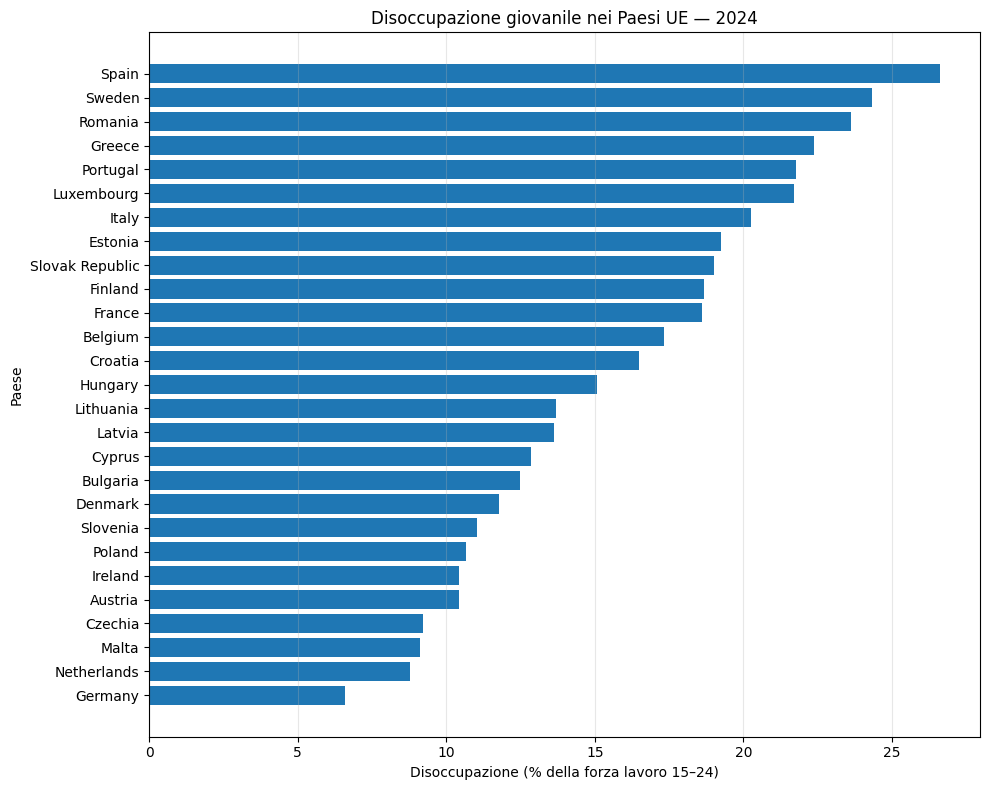

In [6]:
df_2024 = df_paesi[df_paesi["anno"] == 2024].sort_values(
    "disoccupazione_giovanile_percentuale"
)

print("Paesi con un dato nel 2024:", len(df_2024))

plt.figure(figsize=(10, 8))
plt.barh(
    df_2024["paese"],
    df_2024["disoccupazione_giovanile_percentuale"]
)

plt.title("Disoccupazione giovanile nei Paesi UE — 2024")
plt.xlabel("Disoccupazione (% della forza lavoro 15–24)")
plt.ylabel("Paese")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
valori_2024 = df_2024["disoccupazione_giovanile_percentuale"]

print("Media dei 27 Paesi:", round(valori_2024.mean(), 2), "%")
print("Mediana dei 27 Paesi:", round(valori_2024.median(), 2), "%")
print("Minimo:", round(valori_2024.min(), 2), "%")
print("Massimo:", round(valori_2024.max(), 2), "%")

Media dei 27 Paesi: 15.77 %
Mediana dei 27 Paesi: 15.09 %
Minimo: 6.6 %
Massimo: 26.63 %


In [8]:
url_pil = (
    f"https://api.worldbank.org/v2/country/{codici_ue}/"
    "indicator/NY.GDP.PCAP.KD.ZG"
    "?date=2000:2024&format=json&per_page=1000"
)

risposta_pil = requests.get(url_pil)
risposta_pil.raise_for_status()

record_pil = risposta_pil.json()[1]
df_pil = pd.DataFrame(record_pil)

df_pil["paese"] = df_pil["country"].apply(
    lambda paese: paese["value"]
)

df_pil = df_pil.rename(columns={
    "date": "anno",
    "value": "crescita_pil_pro_capite_percentuale"
})

df_pil = df_pil[
    ["paese", "anno", "crescita_pil_pro_capite_percentuale"]
].dropna()

df_pil["anno"] = df_pil["anno"].astype(int)

df_analisi = df_paesi.merge(
    df_pil,
    on=["paese", "anno"],
    how="inner"
)

print("Dimensioni dei dati abbinati:", df_analisi.shape)
print(df_analisi.head(10).to_string(index=False))

Dimensioni dei dati abbinati: (675, 4)
  paese  anno  disoccupazione_giovanile_percentuale  crescita_pil_pro_capite_percentuale
Austria  2000                                 6.285                             2.941685
Austria  2001                                 6.001                             0.929888
Austria  2002                                 7.137                             0.986312
Austria  2003                                 7.429                             0.650068
Austria  2004                                10.991                             1.930897
Austria  2005                                11.178                             1.625659
Austria  2006                                10.046                             2.759624
Austria  2007                                 9.596                             3.439385
Austria  2008                                 8.720                             1.136211
Austria  2009                                10.896                    

In [9]:
correlazione = df_analisi[
    [
        "disoccupazione_giovanile_percentuale",
        "crescita_pil_pro_capite_percentuale"
    ]
].corr().iloc[0, 1]
print("Correlazione:", round(correlazione, 3))

Correlazione: -0.095


In [10]:
correlazione_per_anno = (
    df_analisi
    .groupby("anno")
    .apply(
        lambda gruppo: gruppo[
            [
                "disoccupazione_giovanile_percentuale",
                "crescita_pil_pro_capite_percentuale"
            ]
        ].corr().iloc[0, 1]
    )
    .reset_index(name="correlazione")
)

print(correlazione_per_anno.to_string(index=False))

 anno  correlazione
 2000     -0.121050
 2001      0.458620
 2002      0.421795
 2003      0.513193
 2004      0.333572
 2005     -0.008698
 2006      0.055294
 2007     -0.105794
 2008     -0.004997
 2009     -0.420482
 2010     -0.239416
 2011     -0.301985
 2012     -0.385710
 2013     -0.369930
 2014     -0.253840
 2015     -0.055870
 2016      0.012282
 2017     -0.243911
 2018     -0.175015
 2019     -0.196019
 2020     -0.457382
 2021      0.104449
 2022      0.245998
 2023      0.258909
 2024     -0.079892


/tmp/ipykernel_32286/2015386360.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


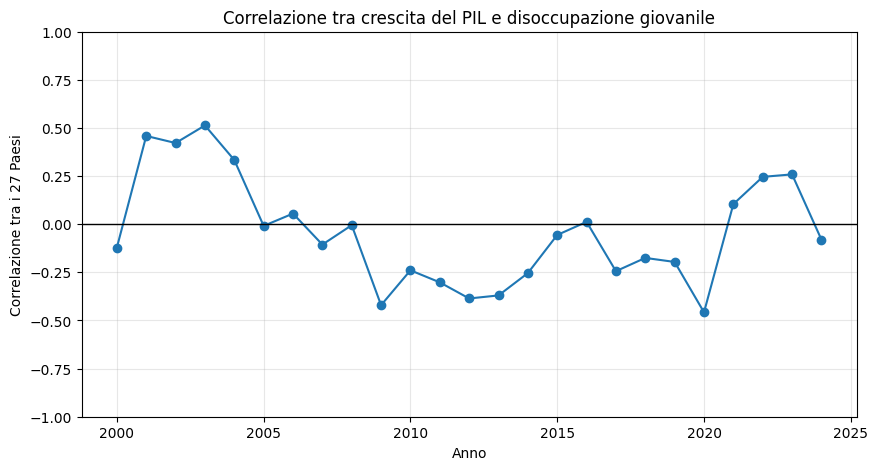

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    correlazione_per_anno["anno"],
    correlazione_per_anno["correlazione"],
    marker="o"
)

plt.axhline(0, color="black", linewidth=1)
plt.ylim(-1, 1)
plt.title("Correlazione tra crescita del PIL e disoccupazione giovanile")
plt.xlabel("Anno")
plt.ylabel("Correlazione tra i 27 Paesi")
plt.grid(True, alpha=0.3)
plt.show()

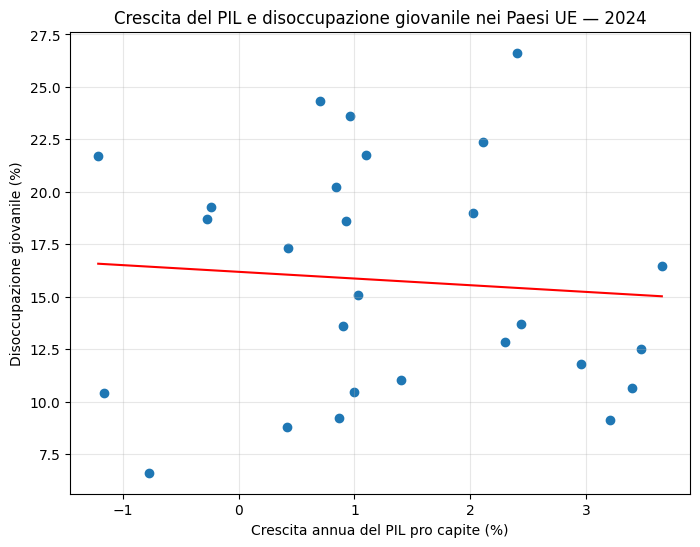

In [12]:
import numpy as np

dati_2024 = df_analisi[df_analisi["anno"] == 2024]

x = dati_2024["crescita_pil_pro_capite_percentuale"]
y = dati_2024["disoccupazione_giovanile_percentuale"]

pendenza, intercetta = np.polyfit(x, y, 1)
x_linea = np.linspace(x.min(), x.max(), 100)

plt.figure(figsize=(8, 6))
plt.scatter(x, y)
plt.plot(x_linea, pendenza * x_linea + intercetta, color="red")

plt.title("Crescita del PIL e disoccupazione giovanile nei Paesi UE — 2024")
plt.xlabel("Crescita annua del PIL pro capite (%)")
plt.ylabel("Disoccupazione giovanile (%)")
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
url_istruzione = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/edat_lfse_03"
)

parametri_istruzione = {
    "lang": "EN",
    "geoLevel": "country",
    "freq": "A",
    "unit": "PC",
    "isced11": "ED3-8",
    "sex": "T",
    "age": "Y20-24",
    "sinceTimePeriod": "2014",
    "untilTimePeriod": "2024"
}

risposta_istruzione = requests.get(
    url_istruzione,
    params=parametri_istruzione
)
risposta_istruzione.raise_for_status()

json_istruzione = risposta_istruzione.json()

print("Dataset:", json_istruzione["label"])
print("Dimensioni:", json_istruzione["id"])
print("Valori ricevuti:", len(json_istruzione["value"]))

Dataset: Population in private households by educational attainment level
Dimensioni: ['freq', 'sex', 'age', 'unit', 'isced11', 'geo', 'time']
Valori ricevuti: 380


In [14]:
from itertools import product

dimensioni = json_istruzione["id"]
dimensioni_lunghezze = json_istruzione["size"]

codici_per_dimensione = [
    list(json_istruzione["dimension"][dimensione]["category"]["index"])
    for dimensione in dimensioni
]

valori = json_istruzione["value"]
righe_istruzione = []

for combinazione in product(*codici_per_dimensione):
    indice = 0

    for dimensione, codice in zip(dimensioni, combinazione):
        posizione = json_istruzione["dimension"][dimensione][
            "category"
        ]["index"][codice]
        indice = indice * len(
            json_istruzione["dimension"][dimensione]["category"]["index"]
        ) + posizione

    if isinstance(valori, dict):
        valore = valori.get(str(indice))
    else:
        valore = valori[indice]

    if valore is not None:
        codici = dict(zip(dimensioni, combinazione))
        nomi = json_istruzione["dimension"]

        righe_istruzione.append({
            "codice_paese": codici["geo"],
            "paese": nomi["geo"]["category"]["label"][codici["geo"]],
            "anno": int(codici["time"]),
            "istruzione_percentuale": valore
        })

df_istruzione = pd.DataFrame(righe_istruzione)

codici_ue_eurostat = [
    "AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI",
    "FR", "DE", "EL", "HU", "IE", "IT", "LV", "LT", "LU",
    "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"
]

df_istruzione = df_istruzione[
    df_istruzione["codice_paese"].isin(codici_ue_eurostat)
].sort_values(["paese", "anno"]).reset_index(drop=True)

print("Dimensioni:", df_istruzione.shape)
print("Paesi UE presenti:", df_istruzione["paese"].nunique())
print("Anni presenti:", sorted(df_istruzione["anno"].unique()))
print(df_istruzione.head(10).to_string(index=False))

Dimensioni: (297, 4)
Paesi UE presenti: 27
Anni presenti: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
codice_paese   paese  anno  istruzione_percentuale
          AT Austria  2014                    89.6
          AT Austria  2015                    88.7
          AT Austria  2016                    89.5
          AT Austria  2017                    87.4
          AT Austria  2018                    88.0
          AT Austria  2019                    87.3
          AT Austria  2020                    86.1
          AT Austria  2021                    86.2
          AT Austria  2022                    85.4
          AT Austria  2023                    85.1


Paesi con un dato nel 2024: 27


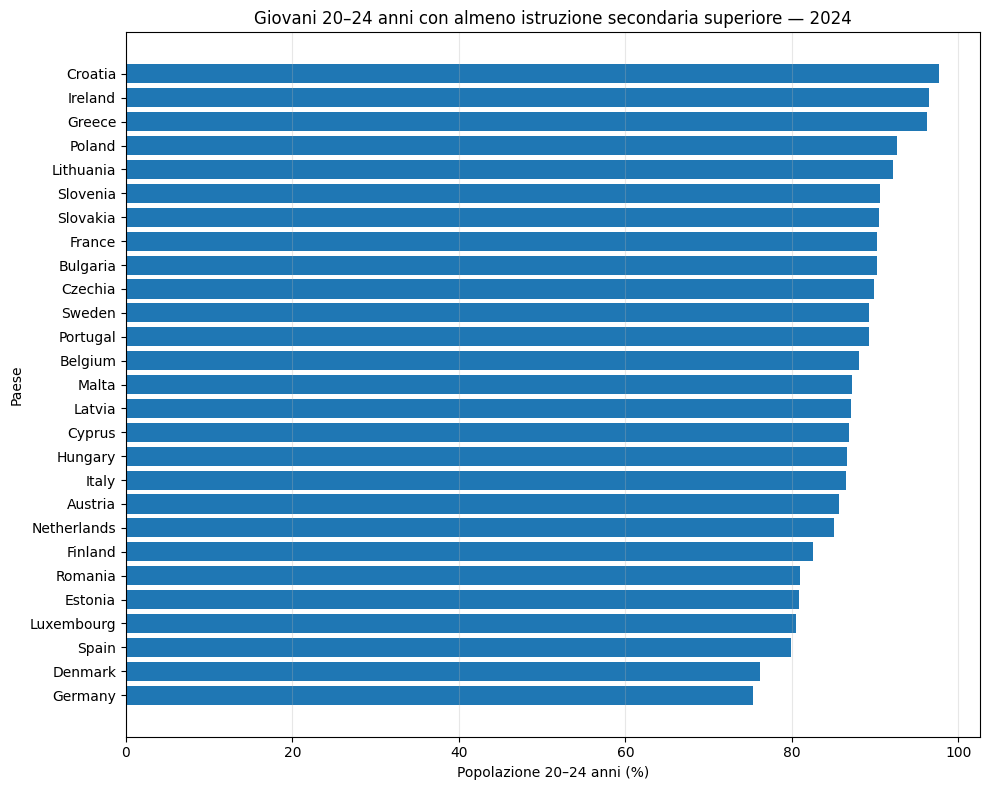

In [15]:
df_istruzione_2024 = df_istruzione[
    df_istruzione["anno"] == 2024
].sort_values("istruzione_percentuale")

print("Paesi con un dato nel 2024:", len(df_istruzione_2024))

plt.figure(figsize=(10, 8))
plt.barh(
    df_istruzione_2024["paese"],
    df_istruzione_2024["istruzione_percentuale"]
)

plt.title(
    "Giovani 20–24 anni con almeno istruzione secondaria superiore — 2024"
)
plt.xlabel("Popolazione 20–24 anni (%)")
plt.ylabel("Paese")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Ricaviamo i nomi dei Paesi usati dalla Banca Mondiale
nomi_wb_per_codice = {
    record["country"]["id"]: record["country"]["value"]
    for record in record_paesi
}

# Sostituiamo il nome Eurostat con il nome corrispondente della Banca Mondiale
df_istruzione["paese"] = df_istruzione["codice_paese"].map(
    nomi_wb_per_codice
)

print("Paesi senza corrispondenza:", df_istruzione["paese"].isna().sum())

# Uniamo i tre indicatori usando Paese e anno
df_completo = df_analisi.merge(
    df_istruzione[["paese", "anno", "istruzione_percentuale"]],
    on=["paese", "anno"],
    how="inner"
)

# Teniamo gli anni per cui è disponibile l'indicatore d'istruzione
df_completo = df_completo[df_completo["anno"] >= 2014].copy()

print("Dimensioni:", df_completo.shape)
print("Paesi:", df_completo["paese"].nunique())
print("Anni:", sorted(df_completo["anno"].unique()))
print(df_completo.head(10).to_string(index=False))

Paesi senza corrispondenza: 11
Dimensioni: (286, 5)
Paesi: 26
Anni: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
  paese  anno  disoccupazione_giovanile_percentuale  crescita_pil_pro_capite_percentuale  istruzione_percentuale
Austria  2014                                10.508                            -0.028581                    89.6
Austria  2015                                10.910                             0.174260                    88.7
Austria  2016                                11.424                             1.018877                    89.5
Austria  2017                                 9.971                             1.564307                    87.4
Austria  2018                                 9.572                             1.986263                    88.0
Austria  2019                                 8.767                          

In [17]:
codici_senza_nome = sorted(
    df_istruzione.loc[
        df_istruzione["paese"].isna(),
        "codice_paese"
    ].unique()
)

print("Codici Eurostat senza corrispondenza:", codici_senza_nome)

Codici Eurostat senza corrispondenza: ['EL']


In [18]:
nomi_wb_per_codice["EL"] = "Greece"

df_istruzione["paese"] = df_istruzione["codice_paese"].map(
    nomi_wb_per_codice
)

df_completo = df_analisi.merge(
    df_istruzione[["paese", "anno", "istruzione_percentuale"]],
    on=["paese", "anno"],
    how="inner"
)

df_completo = df_completo[df_completo["anno"] >= 2014].copy()

print("Dimensioni:", df_completo.shape)
print("Paesi:", df_completo["paese"].nunique())
print("Anni:", sorted(df_completo["anno"].unique()))

Dimensioni: (297, 5)
Paesi: 27
Anni: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


Correlazione nel 2024: -0.049


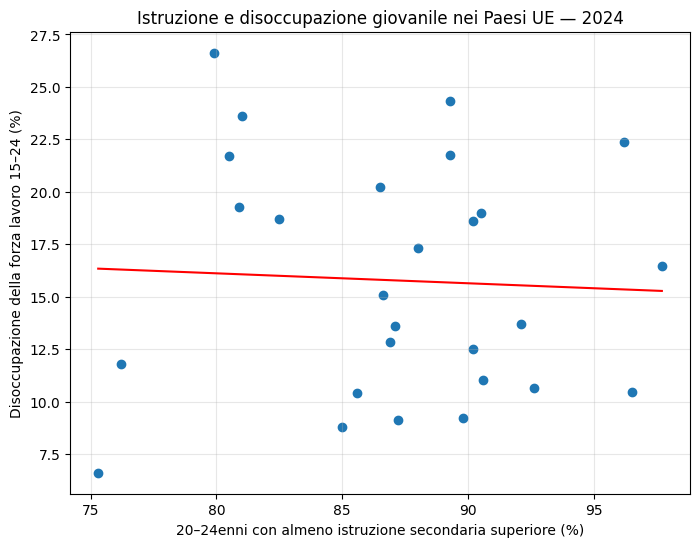

In [19]:
dati_2024 = df_completo[df_completo["anno"] == 2024]

x = dati_2024["istruzione_percentuale"]
y = dati_2024["disoccupazione_giovanile_percentuale"]

correlazione_istruzione_disoccupazione = x.corr(y)
print(
    "Correlazione nel 2024:",
    round(correlazione_istruzione_disoccupazione, 3)
)

pendenza, intercetta = np.polyfit(x, y, 1)
x_linea = np.linspace(x.min(), x.max(), 100)

plt.figure(figsize=(8, 6))
plt.scatter(x, y)
plt.plot(x_linea, pendenza * x_linea + intercetta, color="red")

plt.title("Istruzione e disoccupazione giovanile nei Paesi UE — 2024")
plt.xlabel("20–24enni con almeno istruzione secondaria superiore (%)")
plt.ylabel("Disoccupazione della forza lavoro 15–24 (%)")
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
risultati_istruzione = []

for anno, gruppo in df_completo.groupby("anno"):
    correlazione = gruppo["istruzione_percentuale"].corr(
        gruppo["disoccupazione_giovanile_percentuale"]
    )

    risultati_istruzione.append({
        "anno": anno,
        "correlazione": correlazione
    })

correlazione_istruzione_per_anno = pd.DataFrame(
    risultati_istruzione
)

print(
    correlazione_istruzione_per_anno.to_string(index=False)
)

 anno  correlazione
 2014     -0.056073
 2015      0.060917
 2016     -0.030001
 2017      0.009865
 2018      0.029443
 2019     -0.019778
 2020     -0.052754
 2021      0.058997
 2022     -0.028654
 2023      0.036491
 2024     -0.049084


In [21]:
risultati_istruzione_pil = []

for anno, gruppo in df_completo.groupby("anno"):
    correlazione = gruppo["istruzione_percentuale"].corr(
        gruppo["crescita_pil_pro_capite_percentuale"]
    )

    risultati_istruzione_pil.append({
        "anno": anno,
        "correlazione": correlazione
    })

correlazione_istruzione_pil_per_anno = pd.DataFrame(
    risultati_istruzione_pil
)

print(
    correlazione_istruzione_pil_per_anno.to_string(index=False)
)

 anno  correlazione
 2014      0.136345
 2015      0.317519
 2016      0.051088
 2017      0.285587
 2018      0.515398
 2019      0.512672
 2020      0.162935
 2021      0.560166
 2022      0.449464
 2023      0.189871
 2024      0.439499


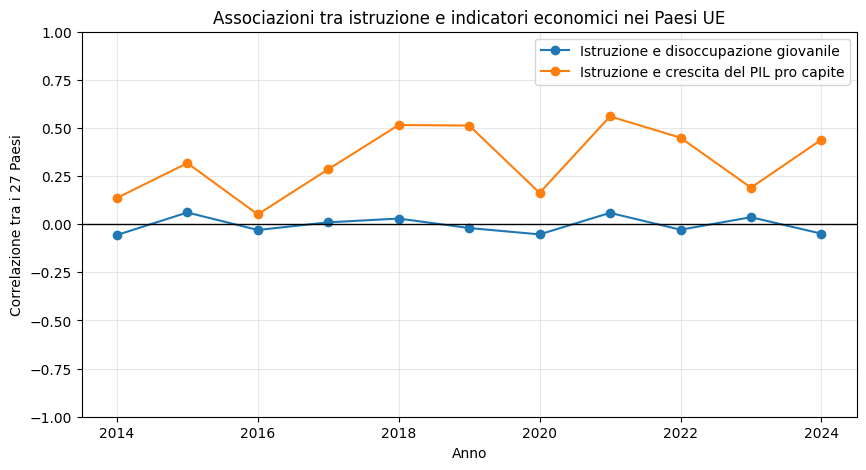

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    correlazione_istruzione_per_anno["anno"],
    correlazione_istruzione_per_anno["correlazione"],
    marker="o",
    label="Istruzione e disoccupazione giovanile"
)

plt.plot(
    correlazione_istruzione_pil_per_anno["anno"],
    correlazione_istruzione_pil_per_anno["correlazione"],
    marker="o",
    label="Istruzione e crescita del PIL pro capite"
)

plt.axhline(0, color="black", linewidth=1)
plt.ylim(-1, 1)
plt.title("Associazioni tra istruzione e indicatori economici nei Paesi UE")
plt.xlabel("Anno")
plt.ylabel("Correlazione tra i 27 Paesi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
dati_2014 = df_completo[df_completo["anno"] == 2014].set_index("paese")
dati_2024 = df_completo[df_completo["anno"] == 2024].set_index("paese")

variazioni = pd.DataFrame({
    "variazione_istruzione_pp": (
        dati_2024["istruzione_percentuale"]
        - dati_2014["istruzione_percentuale"]
    ),
    "variazione_disoccupazione_pp": (
        dati_2024["disoccupazione_giovanile_percentuale"]
        - dati_2014["disoccupazione_giovanile_percentuale"]
    )
})

correlazione_variazioni = variazioni[
    "variazione_istruzione_pp"
].corr(variazioni["variazione_disoccupazione_pp"])

print("Paesi confrontati:", len(variazioni))
print("Correlazione tra i cambiamenti:", round(correlazione_variazioni, 3))
print(variazioni.sort_values("variazione_istruzione_pp").head().round(2))
print(variazioni.sort_values("variazione_istruzione_pp").tail().round(2))

Paesi confrontati: 27
Correlazione tra i cambiamenti: -0.369
         variazione_istruzione_pp  variazione_disoccupazione_pp
paese                                                          
Cyprus                       -5.5                        -22.66
Austria                      -4.0                         -0.08
Finland                      -3.8                         -1.77
Estonia                      -2.1                          4.28
Germany                      -1.8                         -1.01
            variazione_istruzione_pp  variazione_disoccupazione_pp
paese                                                             
Luxembourg                       6.8                         -2.59
Malta                            7.4                         -2.58
Greece                           7.8                        -30.27
Spain                           14.1                        -26.54
Portugal                        17.0                        -12.90


Correlazione di Pearson: -0.369
Correlazione di Spearman: -0.353


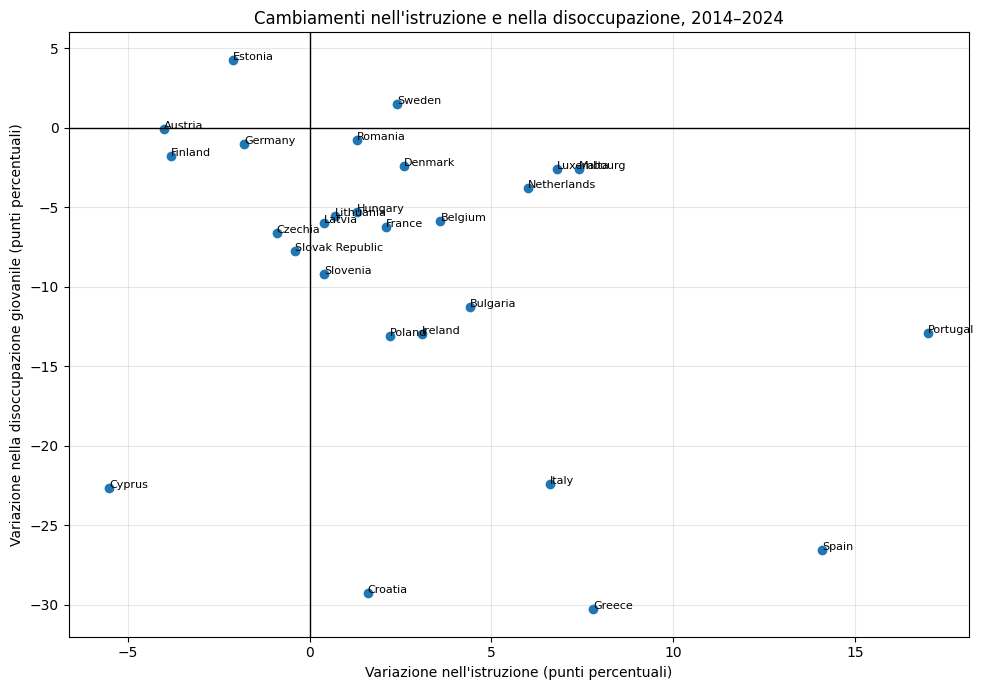

In [24]:
pearson = variazioni[
    "variazione_istruzione_pp"
].corr(variazioni["variazione_disoccupazione_pp"])

spearman = variazioni[
    "variazione_istruzione_pp"
].corr(
    variazioni["variazione_disoccupazione_pp"],
    method="spearman"
)

print("Correlazione di Pearson:", round(pearson, 3))
print("Correlazione di Spearman:", round(spearman, 3))

plt.figure(figsize=(10, 7))

plt.scatter(
    variazioni["variazione_istruzione_pp"],
    variazioni["variazione_disoccupazione_pp"]
)

for paese, riga in variazioni.iterrows():
    plt.annotate(
        paese,
        (
            riga["variazione_istruzione_pp"],
            riga["variazione_disoccupazione_pp"]
        ),
        fontsize=8
    )

plt.axhline(0, color="black", linewidth=1)
plt.axvline(0, color="black", linewidth=1)
plt.title("Cambiamenti nell'istruzione e nella disoccupazione, 2014–2024")
plt.xlabel("Variazione nell'istruzione (punti percentuali)")
plt.ylabel("Variazione nella disoccupazione giovanile (punti percentuali)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
risultati_sensibilita = []

for paese in variazioni.index:
    dati_senza_un_paese = variazioni.drop(index=paese)

    correlazione_senza_paese = dati_senza_un_paese[
        "variazione_istruzione_pp"
    ].corr(
        dati_senza_un_paese["variazione_disoccupazione_pp"]
    )

    risultati_sensibilita.append({
        "paese_escluso": paese,
        "correlazione": correlazione_senza_paese
    })

df_sensibilita = pd.DataFrame(risultati_sensibilita)

print(
    "Correlazione minima togliendo un Paese:",
    round(df_sensibilita["correlazione"].min(), 3)
)
print(
    "Correlazione massima togliendo un Paese:",
    round(df_sensibilita["correlazione"].max(), 3)
)
print("\nEsclusioni che cambiano di più il risultato:")
print(
    df_sensibilita.assign(
        distanza_dal_risultato=lambda tabella:
            (tabella["correlazione"] + 0.369).abs()
    )
    .sort_values("distanza_dal_risultato", ascending=False)
    .head(5)
    .round(3)
    .to_string(index=False)
)

Correlazione minima togliendo un Paese: -0.51
Correlazione massima togliendo un Paese: -0.246

Esclusioni che cambiano di più il risultato:
paese_escluso  correlazione  distanza_dal_risultato
       Cyprus        -0.510                   0.141
        Spain        -0.246                   0.123
      Croatia        -0.429                   0.060
       Greece        -0.319                   0.050
        Malta        -0.405                   0.036


In [26]:
r = variazioni["variazione_istruzione_pp"].corr(
    variazioni["variazione_disoccupazione_pp"]
)
n = len(variazioni)

# Intervallo approssimato al 95% con la trasformazione di Fisher
z = np.arctanh(r)
errore_standard = 1 / np.sqrt(n - 3)

limite_inferiore = np.tanh(z - 1.96 * errore_standard)
limite_superiore = np.tanh(z + 1.96 * errore_standard)

print("Correlazione di Pearson:", round(r, 3))
print(
    "Intervallo approssimato al 95%:",
    (round(limite_inferiore, 3), round(limite_superiore, 3))
)

Correlazione di Pearson: -0.369
Intervallo approssimato al 95%: (np.float64(-0.657), np.float64(0.013))


## Risultati preliminari

L’analisi comprende 27 Paesi dell’Unione Europea e 297 osservazioni Paese-anno tra il 2014 e il 2024.

Nel 2024, la media non ponderata dei tassi nazionali di disoccupazione giovanile è stata del 15,77%; la mediana del 15,09%. I valori nazionali sono compresi tra il 6,60% e il 26,63%.

Tra i Paesi, la correlazione annuale tra istruzione e disoccupazione giovanile è rimasta vicina a zero in tutti gli anni (da −0,056 a +0,061). La correlazione annuale tra istruzione e crescita del PIL pro capite è stata invece positiva, ma variabile (da 0,051 a 0,560).

Confrontando le variazioni tra il 2014 e il 2024, la correlazione tra il cambiamento della quota di giovani con almeno un diploma superiore e il cambiamento della disoccupazione giovanile è stata negativa: Pearson r = −0,369 e Spearman ρ = −0,353. L’intervallo approssimato al 95% per Pearson è [−0,657; 0,013] e comprende lo zero. La correlazione resta negativa togliendo un Paese alla volta, ma la sua intensità varia da −0,246 a −0,510.

## Interpretazione e limiti

I risultati descrivono associazioni tra Paesi; non dimostrano che l’istruzione causi una riduzione della disoccupazione o una crescita economica maggiore. Le correlazioni annuali confrontano 27 Paesi per volta e possono riflettere differenze strutturali non considerate nell’analisi.

Gli indicatori non si riferiscono esattamente alla stessa fascia d’età: l’istruzione misura la quota di 20–24enni che ha completato almeno l’istruzione secondaria superiore, mentre la disoccupazione riguarda la forza lavoro di 15–24 anni. La media del 15,77% assegna lo stesso peso a ciascun Paese; non è il tasso aggregato dell’Unione Europea.

## Fonti

- Disoccupazione giovanile: [Banca Mondiale, indicatore SL.UEM.1524.ZS](https://data.worldbank.org/indicator/SL.UEM.1524.ZS).
- Crescita del PIL pro capite: [Banca Mondiale, indicatore NY.GDP.PCAP.KD.ZG](https://data.worldbank.org/indicator/NY.GDP.PCAP.KD.ZG).
- Istruzione: [Eurostat, persone di 20–24 anni con almeno istruzione secondaria superiore](https://ec.europa.eu/eurostat/databrowser/view/tps00186/default/table).